# Linear regression, workshop 2 — Walking downhill

Last week you solved the bakery problem exactly: one formula, the best line, done. So why does
every machine-learning course spend a month on **gradient descent**?

Because the exact formula is a privilege of linear least squares. The moment your model is a
logistic regression, a random forest's leaf weights, or a neural network, there is no formula —
there is only a cost you can evaluate and a direction you can estimate. Gradient descent is the
method that still works when the clever shortcut does not.

Today, on the same bakery data:

1. **The gradient** — which way is downhill, computed rather than guessed.
2. **The update rule** — the three symbols that train almost every model you will ever use.
3. **The path** — watching the walk across the cost surface.
4. **Convexity** — why, here, every starting point leads to the same place.

In [ ]:
# ABOUTME: Linear regression workshop 2 - gradient descent on the mean squared error.
# ABOUTME: Same bakery data as workshop 1: iced-coffee sales against afternoon temperature.
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

def ready(*values):
    """True once the exercises a cell depends on have been filled in."""
    return all(v is not None for v in values)

n = 120
temperature = rng.uniform(8, 34, n)
sales = np.maximum(12 + 3.1 * temperature + rng.normal(0, 9, n), 0)

def predict(x, theta):
    """theta = (intercept, slope), as in workshop 1."""
    return theta[0] + theta[1] * np.asarray(x)

def mse(theta, x=temperature, y=sales):
    return float(np.mean((predict(x, theta) - y) ** 2))

# The exact answer from workshop 1, kept as the target to hit.
dx, dy = temperature - temperature.mean(), sales - sales.mean()
slope_exact = (dx * dy).sum() / (dx ** 2).sum()
theta_exact = (sales.mean() - slope_exact * temperature.mean(), slope_exact)
print("exact solution:", np.round(theta_exact, 4), " MSE:", round(mse(theta_exact), 3))

exact solution: [12.021   3.0951]  MSE: 82.253


## 1. The cost is a landscape

With two parameters, the MSE is a surface: a height above every $(\theta_0, \theta_1)$ point. For
squared error it is a **bowl** — one lowest point, no ridges, no false bottoms.

Training is the search for the bottom of that bowl, and gradient descent searches it the way you
would walk down a hill in fog: feel which way is steepest, take a step, repeat.

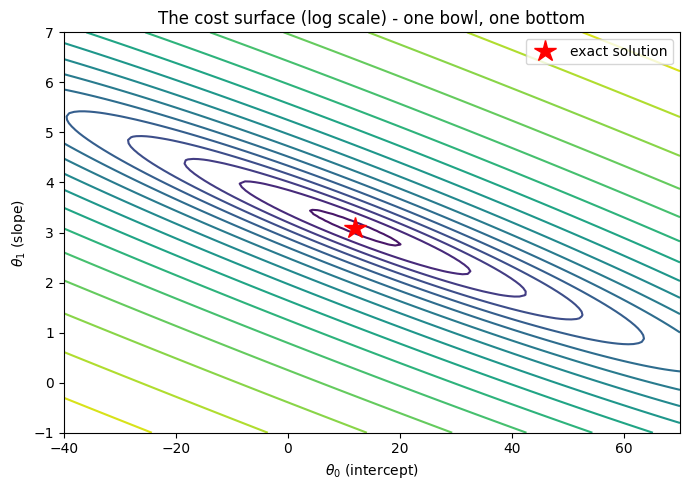

In [ ]:
i_grid = np.linspace(-40, 70, 120)      # candidate intercepts
s_grid = np.linspace(-1, 7, 120)        # candidate slopes
II, SS = np.meshgrid(i_grid, s_grid)
COST = np.array([[mse((i, s)) for i in i_grid] for s in s_grid])

fig, ax = plt.subplots(figsize=(7, 5))
contours = ax.contour(II, SS, np.log10(COST), levels=18, cmap="viridis")
ax.plot(theta_exact[0], theta_exact[1], "r*", markersize=16, label="exact solution")
ax.set_xlabel(r"$\theta_0$ (intercept)"); ax.set_ylabel(r"$\theta_1$ (slope)")
ax.set_title("The cost surface (log scale) - one bowl, one bottom")
ax.legend(); plt.tight_layout()

## 2. The gradient

The gradient is the vector of partial derivatives: for each parameter, *how fast does the cost
change if I nudge this one?* It points **uphill**, which is why the update subtracts it.

For the mean squared error with predictions $\hat{y} = \theta_0 + \theta_1 x$:

$$\frac{\partial \text{MSE}}{\partial \theta_0} = \frac{2}{m}\sum (\hat{y}_i - y_i)
\qquad
\frac{\partial \text{MSE}}{\partial \theta_1} = \frac{2}{m}\sum (\hat{y}_i - y_i)\, x_i$$

Both are averages of the error — the first plain, the second weighted by the feature. Read them
in words: *if I am predicting too high on average, lower the intercept; if I am predicting too high
mostly on hot days, lower the slope.*

### Exercise 1 — the gradient

In [ ]:
def gradient(theta, x=temperature, y=sales):
    """Partial derivatives of the MSE at theta, returned as a numpy array [d/dtheta0, d/dtheta1]."""
    m = len(x)
    error = predict(x, theta) - y          # the common factor of both partials
    return np.array([2 / m * error.sum(), 2 / m * (error * x).sum()])

print("gradient at the exact solution:", gradient(theta_exact), "(should be about [0, 0])")
print("gradient at a bad guess       :", gradient((0.0, 0.0)))

gradient at the exact solution: [1.80004160e-14 4.03588274e-13] (should be about [0, 0])
gradient at a bad guess       : [ -153.83051468 -3536.25157908]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("two partial derivatives", lambda: np.asarray(gradient((1.0, 1.0))).shape == (2,))
check("flat at the minimum", lambda: np.allclose(gradient(theta_exact), 0, atol=1e-6))
check("under-predicting gives a negative gradient", lambda: gradient((0.0, 0.0))[0] < 0)
check("matches a numerical derivative",
      lambda: abs(gradient((10.0, 2.0))[0]
                  - (mse((10.0 + 1e-5, 2.0)) - mse((10.0 - 1e-5, 2.0))) / 2e-5) < 1e-3)

  two partial derivatives: PASS
  flat at the minimum: PASS
  under-predicting gives a negative gradient: PASS
  matches a numerical derivative: PASS


True

That last check is worth keeping for life: **compare your analytic gradient against a numerical
one**. Nudge a parameter by a tiny amount, see how much the cost moves, divide. If the two disagree,
your derivative is wrong — and a wrong gradient is the single most common reason a model "trains"
without ever learning anything.

## 3. The update rule

$$\theta \leftarrow \theta - \alpha \, \nabla \text{MSE}(\theta)$$

Subtract the gradient (go downhill), scaled by the **learning rate** $\alpha$ (how big a step).
That is the whole algorithm. Everything else in deep learning is refinement of this line.

### Exercise 2 — descend

In [ ]:
def descend(theta0, learning_rate=0.002, iterations=200):
    """Run gradient descent, returning (final theta, history of thetas, history of costs)."""
    theta = np.array(theta0, dtype=float)
    thetas, costs = [theta.copy()], [mse(theta)]
    for _ in range(iterations):
        theta = theta - learning_rate * gradient(theta)
        thetas.append(theta.copy())
        costs.append(mse(theta))
    return theta, np.array(thetas), np.array(costs)

theta_gd, path, costs = descend((0.0, 0.0))
print("gradient descent:", np.round(theta_gd, 4))
print("exact solution  :", np.round(theta_exact, 4))

gradient descent: [1.0874 3.5614]
exact solution  : [12.021   3.0951]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("history has one entry per iteration plus the start", lambda: len(path) == 201)
check("the cost went down", lambda: costs[-1] < costs[0])
check("it is heading for the exact solution", lambda: abs(theta_gd[1] - theta_exact[1]) < 0.5)

  history has one entry per iteration plus the start: PASS
  the cost went down: PASS
  it is heading for the exact solution: PASS


True

## 4. Watch it walk

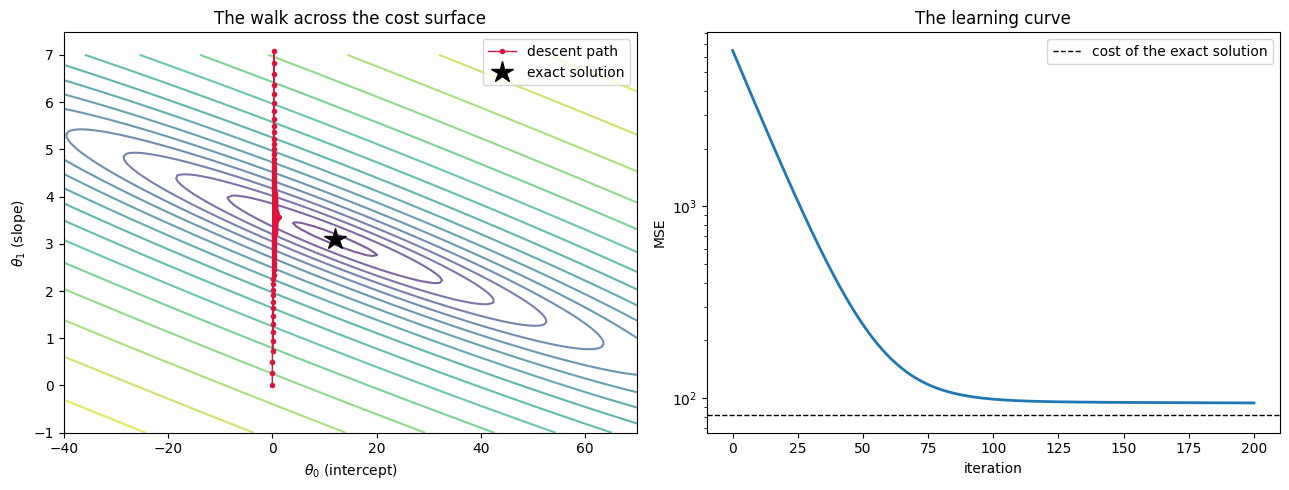

In [ ]:
if not ready(costs if isinstance(costs, np.ndarray) else None):
    print("Finish exercise 2, then run this cell.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].contour(II, SS, np.log10(COST), levels=18, cmap="viridis", alpha=0.7)
    axes[0].plot(path[:, 0], path[:, 1], "o-", color="crimson", ms=3, lw=1, label="descent path")
    axes[0].plot(theta_exact[0], theta_exact[1], "k*", ms=16, label="exact solution")
    axes[0].set_xlabel(r"$\theta_0$ (intercept)"); axes[0].set_ylabel(r"$\theta_1$ (slope)")
    axes[0].set_title("The walk across the cost surface"); axes[0].legend()

    axes[1].plot(costs, lw=2)
    axes[1].axhline(mse(theta_exact), color="k", ls="--", lw=1, label="cost of the exact solution")
    axes[1].set_xlabel("iteration"); axes[1].set_ylabel("MSE"); axes[1].set_yscale("log")
    axes[1].set_title("The learning curve"); axes[1].legend()
    plt.tight_layout()

Two views of one run, and you should learn to read both:

- **Left** — the path shoots almost **straight up** the slope axis and then stops moving visibly. In
  200 iterations the slope travelled from 0 to ~3.6, while the intercept crawled from 0 to ~1 — and
  it still has 11 to go. The contours explain why: they are long diagonal ellipses, so the surface
  is steep in one direction and nearly flat in the other. Descent follows the steep direction first
  and then has to inch along the floor of a long valley.
- **Right** — the learning curve: steep, then apparently flat, and still a visible gap above the
  dashed line. **Flat is not the same as finished.** Plot the cost on a log scale, where "slowly
  still improving" and "completely stuck" look different; on a linear scale both look like success.

That stretched valley is not a quirk of this dataset — it is what happens whenever your features
live on different scales, and it is the subject of the next workshop.

### Exercise 3 — how long to get close?

The exact solution took no iterations. How many does descent need to come within 1 % of its cost?

In [ ]:
target = mse(theta_exact) * 1.01

_, _, long_costs = descend((0.0, 0.0), learning_rate=0.002, iterations=20000)
reached = long_costs <= target
iterations_needed = int(np.argmax(reached)) if reached.any() else None
print("iterations to get within 1% of the best possible cost:", iterations_needed)
print("final cost:", round(float(long_costs[-1]), 4), " exact:", round(mse(theta_exact), 4))

iterations to get within 1% of the best possible cost: 3499
final cost: 82.2531  exact: 82.2531


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("an answer was found", lambda: iterations_needed is not None)
check("it took more than a handful of steps", lambda: iterations_needed > 10)

  an answer was found: PASS
  it took more than a handful of steps: PASS


True

Thousands of iterations to match what one matrix multiplication gave you instantly. On this
problem, gradient descent is strictly the worse tool — and it is still the one that scales to
models where no formula exists.

**Rule of thumb:** use the closed form when you have one. Reach for descent when the model is not
linear, when the data does not fit in memory, or when $X^TX$ is too large to invert.

### Exercise 4 — convexity

The MSE bowl has exactly one bottom. Check it: start descent from three very different corners and
compare where they end up.

In [ ]:
starts = [(-30.0, 6.0), (60.0, -1.0), (0.0, 0.0)]

endings = [descend(s, learning_rate=0.002, iterations=20000)[0] for s in starts]

for start, end in zip(starts, endings):
    print(f"from {start} -> {np.round(end, 3)}")
print("exact solution    ->", np.round(theta_exact, 3))

from (-30.0, 6.0) -> [12.009  3.096]
from (60.0, -1.0) -> [12.034  3.095]
from (0.0, 0.0) -> [12.018  3.095]
exact solution    -> [12.021  3.095]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("three runs", lambda: len(endings) == 3)
check("all three agree", lambda: np.allclose(endings[0], endings[1], atol=0.05)
                                 and np.allclose(endings[1], endings[2], atol=0.05))
check("and they agree with the exact answer", lambda: np.allclose(endings[0], theta_exact, atol=0.1))

  three runs: PASS
  all three agree: PASS
  and they agree with the exact answer: PASS


True

Same destination every time. That is **convexity**, and it is a property of this cost function, not
a general law: train a neural network from three different starting points and you will get three
different models. Enjoy it while it lasts.

## What to take away

1. **The gradient is a direction, computed.** Two averages of the error: one plain, one weighted
   by the feature.
2. **Check your gradient numerically.** A wrong derivative trains silently and forever.
3. **The update rule is one line.** `theta -= learning_rate * gradient` is the engine under almost
   every model you will meet.
4. **Read both plots** — the path over the surface and the cost against iteration, on a log scale.
5. **A long flat valley means a slow walk**, and it is a scaling problem (next workshop).
6. **Convex means one bottom**, so any starting point works. Only linear least squares is this kind.

### Take it home
In your project, `GradientDescentOptimizer` takes any `f` and its `fprime`, not just the MSE. Test
it on a function whose minimum you already know — `f(x) = 3 + (x - [2, 6])^T(x - [2, 6])` is in the
subject — so that a bug shows up as a wrong answer you can recognise immediately.